# How does the number of classes affect softmax and SDM? CIFAR-10 against Imagenette

On CIFAR-100, SDM formed no region on the 100 classes; on Imagenette's 10 classes it did ([notebook 10](10_summary_imagenette_vs_cifar100.ipynb)). This notebook tests the number of classes directly, on two 10-class datasets at the same resolution:

- **CIFAR-10** (32 × 32) and **Imagenette at 32 × 32**, with the **same pipeline**: images stored at 36 × 36, random 32 × 32 crops for training, the central 32 × 32 for evaluation.
- **The same amount of data per class:** 500 training, 200 calibration and 150 validation images per class in both datasets, with a split fixed once per dataset, so an image keeps its role at every K.
- **Nested class sets, K = 2 … 10:** each step keeps every class of the previous step and adds **one randomly chosen new class**. A *chain* is one such random order; there are 3 chains, each with its own training seed, so a jump at some K can be traced to the class added there, and the mean over chains shows the effect of the number of classes itself.
- **At every step:** a fresh ResNet-18 (notebook 08's recipe), a temperature and SDM fitted on calibration, all numbers measured on validation.
- **A free out-of-distribution test:** for K < 10, the validation images of the classes *not yet added* were never seen in training. Any answer on them is wrong, so we can measure how often softmax and SDM wrongly answer them.

The runs are produced by `experiments/class_sweep.py` (about 3 hours for all 54 runs on an Apple M3 Pro, resumable):

```bash
python experiments/class_sweep.py --dataset cifar10 imagenette --chains 3 --k 2-10
```

This notebook only reads the results in `outputs/class_sweep/`. Validation has 150 images per class (300 at K = 2), so per-run numbers carry noticeable noise; the bands show the spread over chains.

## 1. Load the results

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd

RESULTS_DIR = Path("../outputs/class_sweep")
DATASETS = {"cifar10": "CIFAR-10", "imagenette": "Imagenette 32 × 32"}

# One fixed color per dataset in every chart (categorical slots 1 and 2 of the reference palette; orange is
# Imagenette 32 x 32 as in notebook 10). Line style carries the method: solid = softmax, dashed = SDM.
COLORS = {"CIFAR-10": "#2a78d6", "Imagenette 32 × 32": "#eb6834"}
INK, INK_SECONDARY, INK_MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": AXIS, "axes.labelcolor": INK_SECONDARY,
    "axes.titlecolor": INK, "axes.titlesize": 11, "xtick.color": INK_MUTED, "ytick.color": INK_MUTED,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "legend.frameon": False, "legend.fontsize": 8, "lines.linewidth": 2,
})

runs = pd.DataFrame([json.loads(path.read_text()) for path in sorted(RESULTS_DIR.glob("*/chain*_K*/metrics.json"))])
assert len(runs), f"no results in {RESULTS_DIR}: run experiments/class_sweep.py first"
runs["dataset"] = runs["dataset"].map(DATASETS)
runs = runs.sort_values(["dataset", "chain", "k"]).reset_index(drop=True)

expected = {(DATASETS[d], c, k) for d in DATASETS for c in range(runs["chain"].max() + 1) for k in range(2, 11)}
missing = sorted(expected - set(zip(runs["dataset"], runs["chain"], runs["k"])))
print(f"{len(runs)} runs loaded" + (f"; missing {len(missing)}: {missing[:6]}{' ...' if len(missing) > 6 else ''}" if missing else "; sweep complete"))

54 runs loaded; sweep complete


### The class each chain adds at each step

Read across a row: the classes of the K-class task are the first K columns. The first two columns are the starting pair.

In [2]:
orders = (runs[runs["k"] == runs.groupby(["dataset", "chain"])["k"].transform("max")]
          .set_index(["dataset", "chain"]).apply(lambda row: pd.Series(row["classes"] + row["excluded"]), axis=1))
orders.columns = [f"#{i + 1}" for i in orders.columns]
orders

#1             #2               #3  \
dataset            chain                                                    
CIFAR-10           0                 deer           frog             bird   
                   1                 ship           deer            horse   
                   2                 bird       airplane            horse   
Imagenette 32 × 32 0               church  garbage_truck  cassette_player   
                   1            golf_ball         church         gas_pump   
                   2      cassette_player          tench         gas_pump   

                                     #4                #5               #6  \
dataset            chain                                                     
CIFAR-10           0              horse               cat              dog   
                   1           airplane        automobile             bird   
                   2               frog             truck              dog   
Imagenette 32 × 32 0           gas_pump         chain_saw      French_horn   
                   1              tench  English_springer  cassette_player   
                   2      garbage_truck         parachute      French_horn   

                                   #7         #8             #9  \
dataset            chain                                          
CIFAR-10           0            truck   airplane           ship   
                   1              dog      truck           frog   
                   2              cat       deer           ship   
Imagenette 32 × 32 0        parachute      tench      golf_ball   
                   1      French_horn  parachute  garbage_truck   
                   2        chain_saw     church      golf_ball   

                                       #10  
dataset            chain                    
CIFAR-10           0            automobile  
                   1                   cat  
                   2            automobile  
Imagenette 32 × 32 0      English_springer  
                   1             chain_saw  
                   2      English_springer

### Plotting helpers

`plot_vs_k` draws, for each dataset, the **mean over chains** as a line and the **min–max over chains** as a shaded band.

In [3]:
def by_k(column):
    return runs.groupby(["dataset", "k"])[column].agg(["mean", "min", "max"]).reset_index()


def plot_vs_k(ax, column, linestyle="-", band=True):
    for dataset, group in by_k(column).groupby("dataset"):
        ax.plot(group["k"], group["mean"], color=COLORS[dataset], linestyle=linestyle, marker="o", markersize=5,
                markeredgecolor=SURFACE, markeredgewidth=1.5)
        if band:
            ax.fill_between(group["k"], group["min"], group["max"], color=COLORS[dataset], alpha=0.12, linewidth=0)


def legend(ax, styles=(("-", "softmax"), ("--", "SDM")), loc="best"):
    handles = [Line2D([], [], color=color, linewidth=2, label=dataset) for dataset, color in COLORS.items()]
    handles += [Line2D([], [], color=INK_MUTED, linewidth=2, linestyle=style, label=label) for style, label in styles]
    ax.legend(handles=handles, loc=loc)


def percent(ax, axis="y"):
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))


def k_axis(ax):
    ax.set_xticks(range(2, 11))
    ax.set_xlabel("number of classes K")


def table(columns, formats=None):
    # Mean over chains, one row per K and one column block per dataset.
    formats = formats or {}
    out = runs.groupby(["k", "dataset"])[list(columns)].mean().unstack("dataset")
    styles = {f"{columns[metric]} · {dataset}": formats.get(metric, "{:.1%}") for metric, dataset in out.columns}  # keyed by metric
    out.columns = list(styles)
    return out.style.format(styles, na_rep="-")

## 2. Accuracy

Raw accuracy falls with K for any classifier simply because there are more ways to be wrong (chance is 1/K, the dotted gray line). **Chance-adjusted accuracy**, (accuracy − 1/K) / (1 − 1/K), is 0 at chance and 1 when perfect, so it is comparable across K.

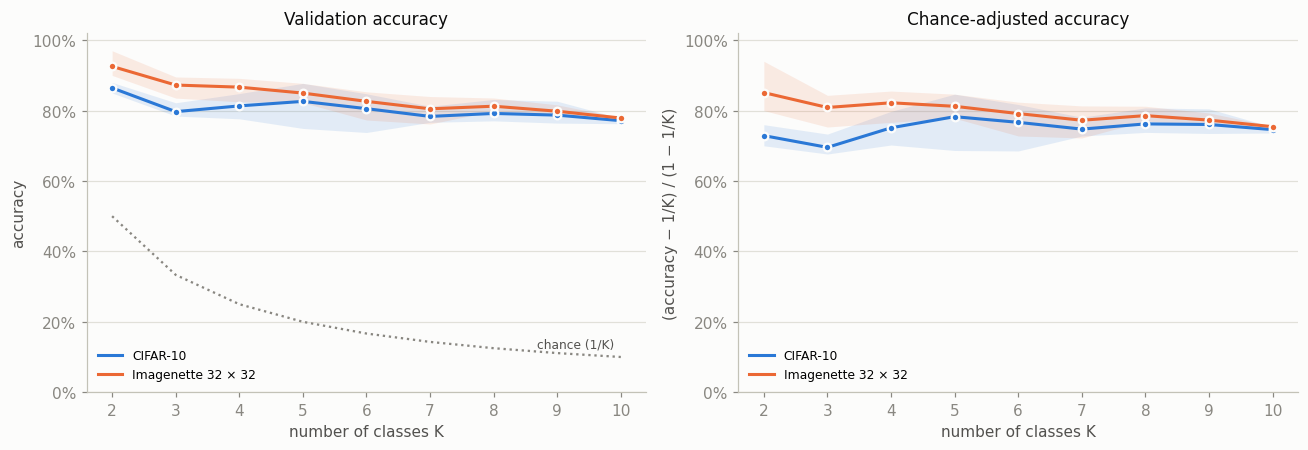

,validation · CIFAR-10,validation · Imagenette 32 × 32,chance-adjusted · CIFAR-10,chance-adjusted · Imagenette 32 × 32,train · CIFAR-10,train · Imagenette 32 × 32
k,,,,,,
2,86.4%,92.6%,72.9%,85.1%,95.0%,98.2%
3,79.7%,87.3%,69.6%,80.9%,95.0%,98.0%
4,81.3%,86.7%,75.1%,82.2%,99.4%,99.8%
5,82.6%,85.0%,78.3%,81.2%,99.9%,99.9%
6,80.6%,82.6%,76.7%,79.2%,100.0%,100.0%
7,78.3%,80.5%,74.7%,77.3%,100.0%,99.9%
8,79.2%,81.2%,76.2%,78.6%,99.9%,99.9%
9,78.7%,79.8%,76.1%,77.3%,99.9%,99.9%
10,77.1%,77.9%,74.6%,75.4%,98.8%,98.4%


In [4]:
fig, (ax_raw, ax_adj) = plt.subplots(1, 2, figsize=(12, 4.2))
plot_vs_k(ax_raw, "val_accuracy")
ks = np.arange(2, 11)
ax_raw.plot(ks, 1 / ks, color=INK_MUTED, linestyle=":", linewidth=1.5)
ax_raw.annotate("chance (1/K)", (ks[-1], 1 / ks[-1]), xytext=(-4, 6), textcoords="offset points", ha="right", fontsize=8, color=INK_SECONDARY)
ax_raw.set(title="Validation accuracy", ylabel="accuracy", ylim=(0, 1.02))
plot_vs_k(ax_adj, "chance_adjusted_accuracy")
ax_adj.set(title="Chance-adjusted accuracy", ylabel="(accuracy − 1/K) / (1 − 1/K)", ylim=(0, 1.02))
for ax in (ax_raw, ax_adj):
    k_axis(ax)
    percent(ax)
    legend(ax, styles=(), loc="lower left")
plt.tight_layout()
plt.show()

table({"val_accuracy": "validation", "chance_adjusted_accuracy": "chance-adjusted", "train_accuracy": "train"})

## 3. Calibration

Expected calibration error (15 bins) on validation, of the raw softmax (dotted) and after temperature scaling (solid), and the fitted temperature (above 1 means the raw softmax was overconfident).

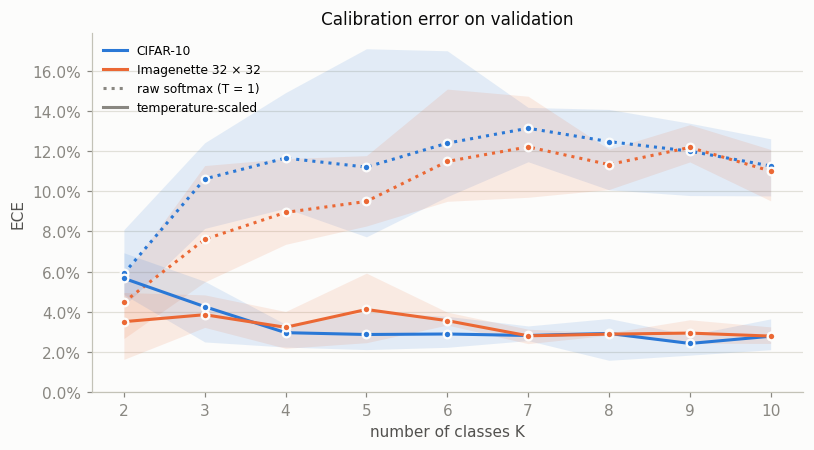

,ECE raw · CIFAR-10,ECE raw · Imagenette 32 × 32,ECE scaled · CIFAR-10,ECE scaled · Imagenette 32 × 32,temperature · CIFAR-10,temperature · Imagenette 32 × 32
k,,,,,,
2,5.9%,4.5%,5.7%,3.5%,1.61,2.51
3,10.6%,7.6%,4.3%,3.9%,2.00,2.23
4,11.6%,8.9%,3.0%,3.2%,2.44,2.82
5,11.2%,9.5%,2.9%,4.1%,2.35,2.69
6,12.4%,11.5%,2.9%,3.6%,2.46,2.68
7,13.1%,12.2%,2.8%,2.8%,2.41,2.50
8,12.5%,11.3%,2.9%,2.9%,2.31,2.43
9,12.0%,12.2%,2.4%,2.9%,2.05,2.30
10,11.3%,11.0%,2.8%,2.8%,1.80,1.92


In [5]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
plot_vs_k(ax, "ece_raw", linestyle=":")
plot_vs_k(ax, "ece_scaled", linestyle="-")
ax.set(title="Calibration error on validation", ylabel="ECE", ylim=(0, None))
k_axis(ax)
percent(ax)
legend(ax, styles=((":", "raw softmax (T = 1)"), ("-", "temperature-scaled")), loc="upper left")
plt.tight_layout()
plt.show()

table({"ece_raw": "ECE raw", "ece_scaled": "ECE scaled", "temperature": "temperature"}, {"temperature": "{:.2f}"})

## 4. Coverage at 95% accuracy: softmax against SDM

- **Softmax:** the temperature-scaled confidence threshold chosen on calibration for 95% selective accuracy (plain rule, as in notebook 04).
- **SDM:** the images inside a region at α ≥ 0.95 (0 if SDM formed no such region).

Left: the share of validation images each rule answers. Right: how accurate those answers are; the dotted line is the 95% target. A rule that answers nothing has no accuracy, so its point is missing.

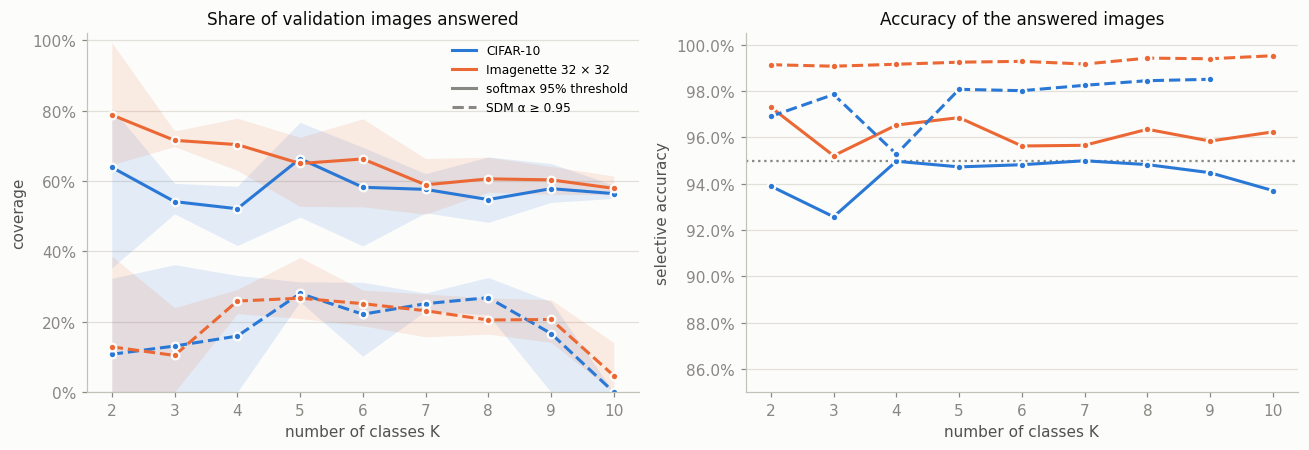

,softmax coverage · CIFAR-10,softmax coverage · Imagenette 32 × 32,softmax accuracy · CIFAR-10,softmax accuracy · Imagenette 32 × 32,SDM α≥0.95 coverage · CIFAR-10,SDM α≥0.95 coverage · Imagenette 32 × 32,SDM α≥0.95 accuracy · CIFAR-10,SDM α≥0.95 accuracy · Imagenette 32 × 32
k,,,,,,,,
2,63.9%,78.8%,93.9%,97.3%,10.8%,12.9%,96.9%,99.1%
3,54.1%,71.6%,92.6%,95.2%,13.1%,10.4%,97.9%,99.1%
4,52.1%,70.3%,95.0%,96.5%,15.9%,25.9%,95.3%,99.2%
5,66.4%,65.0%,94.7%,96.9%,28.0%,26.7%,98.1%,99.2%
6,58.2%,66.3%,94.8%,95.6%,22.1%,25.1%,98.0%,99.3%
7,57.6%,58.9%,95.0%,95.7%,25.1%,23.1%,98.2%,99.2%
8,54.7%,60.6%,94.8%,96.4%,26.9%,20.5%,98.4%,99.4%
9,57.8%,60.3%,94.5%,95.8%,16.7%,20.7%,98.5%,99.4%
10,56.4%,57.9%,93.7%,96.2%,0.0%,4.7%,-,99.5%


In [6]:
fig, (ax_cov, ax_acc) = plt.subplots(1, 2, figsize=(12, 4.2))
plot_vs_k(ax_cov, "softmax_plain_95_coverage")
plot_vs_k(ax_cov, "sdm_coverage_095", linestyle="--")
ax_cov.set(title="Share of validation images answered", ylabel="coverage", ylim=(0, 1.02))
plot_vs_k(ax_acc, "softmax_plain_95_accuracy", band=False)
plot_vs_k(ax_acc, "sdm_accuracy_095", linestyle="--", band=False)
ax_acc.axhline(0.95, color=INK_MUTED, linestyle=":", linewidth=1.5, zorder=0)
ax_acc.set(title="Accuracy of the answered images", ylabel="selective accuracy", ylim=(0.85, 1.005))
for ax in (ax_cov, ax_acc):
    k_axis(ax)
    percent(ax)
legend(ax_cov, styles=(("-", "softmax 95% threshold"), ("--", "SDM α ≥ 0.95")), loc="upper right")
plt.tight_layout()
plt.show()

table({"softmax_plain_95_coverage": "softmax coverage", "softmax_plain_95_accuracy": "softmax accuracy",
       "sdm_coverage_095": "SDM α≥0.95 coverage", "sdm_accuracy_095": "SDM α≥0.95 accuracy"})

## 5. Where SDM forms regions

SDM forms a region at α only if, at one similarity cutoff, **every** class keeps calibration images and nearly all of them get at least α probability for their true class. Left: the highest α at which SDM formed a region, per chain (a hollow marker at the bottom means no region at all). Right: the share of validation images inside any region.

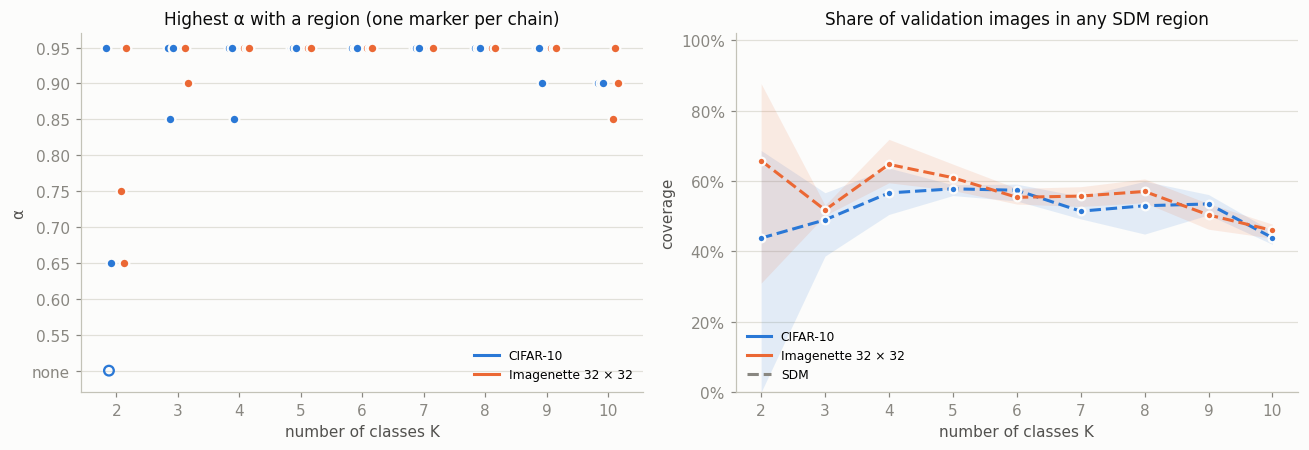

dataset                                        CIFAR-10  \
chain                                                 0   
k                                                         
2        0.95, 0.90, 0.85, 0.80, 0.75, 0.70, 0.65, 0.60   
3                          0.95, 0.90, 0.80, 0.75, 0.70   
4                                      0.95, 0.80, 0.70   
5                          0.95, 0.85, 0.70, 0.60, 0.55   
6                          0.95, 0.90, 0.80, 0.75, 0.60   
7                                0.95, 0.85, 0.75, 0.60   
8                                      0.95, 0.85, 0.70   
9                                0.95, 0.85, 0.70, 0.60   
10                               0.90, 0.80, 0.75, 0.65   

dataset                                      \
chain                                     1   
k                                             
2                                      none   
3              0.85, 0.75, 0.65, 0.60, 0.55   
4        0.95, 0.85, 0.75, 0.70, 0.65, 0.55   
5        0.95, 0.90, 0.80, 0.70, 0.60, 0.55   
6        0.95, 0.90, 0.85, 0.75, 0.65, 0.55   
7              0.95, 0.90, 0.80, 0.70, 0.55   
8              0.95, 0.85, 0.70, 0.65, 0.60   
9        0.95, 0.90, 0.85, 0.80, 0.65, 0.55   
10                         0.90, 0.80, 0.65   

dataset                                                  \
chain                                                 2   
k                                                         
2                                      0.65, 0.60, 0.55   
3        0.95, 0.90, 0.85, 0.80, 0.75, 0.70, 0.60, 0.55   
4                                      0.85, 0.70, 0.60   
5                          0.95, 0.90, 0.85, 0.75, 0.65   
6                    0.95, 0.90, 0.75, 0.70, 0.65, 0.60   
7                                0.95, 0.85, 0.80, 0.65   
8                    0.95, 0.90, 0.80, 0.65, 0.60, 0.55   
9                                0.90, 0.75, 0.60, 0.55   
10                   0.90, 0.80, 0.75, 0.70, 0.65, 0.55   

dataset                        Imagenette 32 × 32  \
chain                                           0   
k                                                   
2                    0.75, 0.70, 0.65, 0.60, 0.55   
3              0.95, 0.90, 0.85, 0.80, 0.75, 0.55   
4        0.95, 0.90, 0.85, 0.75, 0.70, 0.65, 0.60   
5              0.95, 0.90, 0.85, 0.75, 0.65, 0.55   
6              0.95, 0.90, 0.80, 0.70, 0.65, 0.60   
7                          0.95, 0.80, 0.75, 0.60   
8              0.95, 0.90, 0.85, 0.75, 0.65, 0.55   
9        0.95, 0.85, 0.75, 0.70, 0.65, 0.60, 0.55   
10                               0.85, 0.65, 0.55   

dataset                                            \
chain                                           1   
k                                                   
2                                      0.65, 0.55   
3        0.95, 0.90, 0.85, 0.80, 0.75, 0.70, 0.55   
4              0.95, 0.90, 0.85, 0.75, 0.65, 0.55   
5                          0.95, 0.85, 0.70, 0.60   
6        0.95, 0.90, 0.85, 0.80, 0.75, 0.65, 0.55   
7              0.95, 0.90, 0.80, 0.70, 0.60, 0.55   
8                          0.95, 0.85, 0.70, 0.60   
9              0.95, 0.90, 0.85, 0.75, 0.70, 0.60   
10             0.95, 0.85, 0.75, 0.70, 0.65, 0.55   

dataset                                                     
chain                                                    2  
k                                                           
2        0.95, 0.90, 0.85, 0.80, 0.75, 0.70, 0.65, 0.60...  
3                       0.90, 0.80, 0.75, 0.70, 0.60, 0.55  
4                             0.95, 0.90, 0.85, 0.75, 0.55  
5           0.95, 0.90, 0.85, 0.80, 0.75, 0.70, 0.60, 0.55  
6                       0.95, 0.90, 0.80, 0.75, 0.70, 0.60  
7                             0.95, 0.90, 0.85, 0.75, 0.60  
8                             0.95, 0.85, 0.80, 0.70, 0.55  
9                       0.95, 0.90, 0.85, 0.80, 0.65, 0.55  
10                                  0.90, 0.70, 0.60, 0.55

In [7]:
fig, (ax_alpha, ax_any) = plt.subplots(1, 2, figsize=(12, 4.2))
offsets = {dataset: offset for dataset, offset in zip(COLORS, [-0.12, 0.12])}
for (dataset, chain), group in runs.groupby(["dataset", "chain"]):
    x = group["k"] + offsets[dataset] + (chain - 1) * 0.04
    formed = group["sdm_top_alpha"].notna()
    ax_alpha.scatter(x[formed], group["sdm_top_alpha"][formed], s=40, color=COLORS[dataset], edgecolor=SURFACE, linewidth=1.5, zorder=3)
    ax_alpha.scatter(x[~formed], np.full((~formed).sum(), 0.5), s=40, facecolor="none", edgecolor=COLORS[dataset], linewidth=1.5, zorder=3)
ax_alpha.set(title="Highest α with a region (one marker per chain)", ylabel="α", ylim=(0.47, 0.97))
ax_alpha.set_yticks([0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95], labels=["none"] + [f"{a:.2f}" for a in np.arange(0.55, 0.96, 0.05)])
plot_vs_k(ax_any, "sdm_coverage_any", linestyle="--")
ax_any.set(title="Share of validation images in any SDM region", ylabel="coverage", ylim=(0, 1.02))
percent(ax_any)
for ax in (ax_alpha, ax_any):
    k_axis(ax)
legend(ax_alpha, styles=(), loc="lower right")
legend(ax_any, styles=(("--", "SDM"),), loc="lower left")
plt.tight_layout()
plt.show()

(runs.assign(regions=runs["sdm_regions"].map(lambda r: ", ".join(f"{a:.2f}" for a in r) or "none"))
     .pivot_table(index="k", columns=["dataset", "chain"], values="regions", aggfunc="first"))

## 6. Ranking: does SDM order right and wrong answers better?

**E-AURC** is the area under the risk–coverage curve minus that of a perfect ranking with the same mistakes: 0 means right answers always outrank wrong ones. Unlike plain AURC, it does not shrink just because accuracy is higher, so it is comparable across K. Lower is better.

Right: the paired difference **softmax AURC − SDM AURC** for each run, with its 95% bootstrap interval (1,000 resamples of the validation images). Above 0 means SDM ranks better; an interval that crosses 0 means no clear difference.

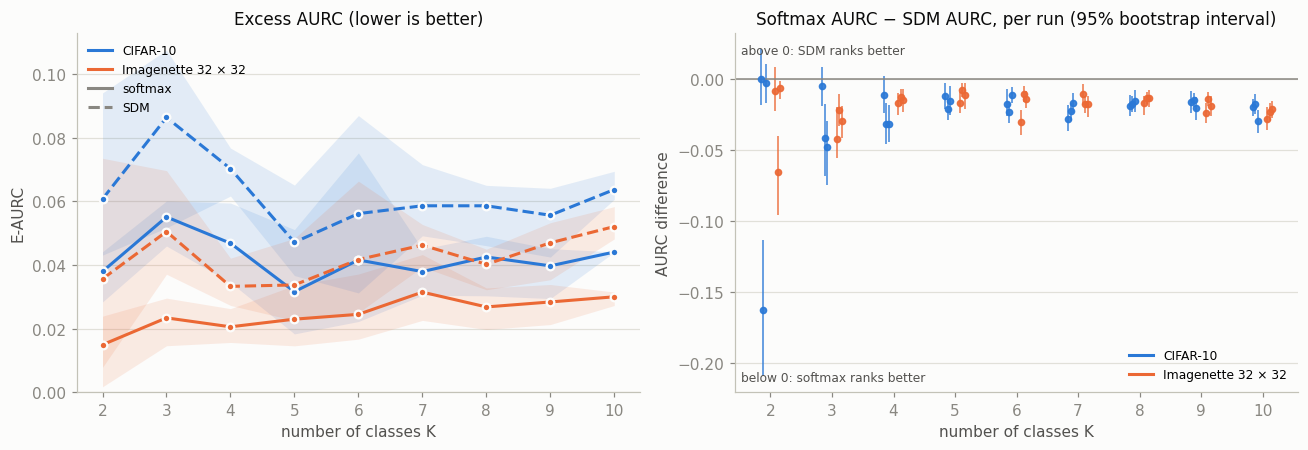

,softmax E-AURC · CIFAR-10,softmax E-AURC · Imagenette 32 × 32,SDM E-AURC · CIFAR-10,SDM E-AURC · Imagenette 32 × 32,softmax AUROC · CIFAR-10,softmax AUROC · Imagenette 32 × 32,SDM AUROC · CIFAR-10,SDM AUROC · Imagenette 32 × 32
k,,,,,,,,
2,0.038,0.015,0.061,0.036,0.795,0.872,0.762,0.782
3,0.055,0.023,0.086,0.051,0.791,0.845,0.712,0.754
4,0.047,0.021,0.070,0.033,0.808,0.866,0.734,0.813
5,0.032,0.023,0.047,0.034,0.853,0.872,0.794,0.828
6,0.042,0.024,0.056,0.042,0.833,0.876,0.787,0.812
7,0.038,0.031,0.059,0.046,0.848,0.859,0.793,0.802
8,0.043,0.027,0.059,0.040,0.829,0.874,0.782,0.825
9,0.040,0.028,0.056,0.047,0.842,0.876,0.796,0.806
10,0.044,0.030,0.064,0.052,0.838,0.878,0.781,0.806


In [8]:
fig, (ax_eaurc, ax_diff) = plt.subplots(1, 2, figsize=(12, 4.2))
plot_vs_k(ax_eaurc, "softmax_e_aurc")
plot_vs_k(ax_eaurc, "sdm_e_aurc", linestyle="--")
ax_eaurc.set(title="Excess AURC (lower is better)", ylabel="E-AURC", ylim=(0, None))
legend(ax_eaurc, loc="upper left")

for (dataset, chain), group in runs.groupby(["dataset", "chain"]):
    x = group["k"] + offsets[dataset] + (chain - 1) * 0.04
    low = group["aurc_softmax_minus_sdm_interval"].map(lambda i: i[0])
    high = group["aurc_softmax_minus_sdm_interval"].map(lambda i: i[1])
    value = group["aurc_softmax_minus_sdm"]
    ax_diff.errorbar(x, value, yerr=[value - low, high - value], fmt="o", markersize=4, color=COLORS[dataset],
                     ecolor=COLORS[dataset], elinewidth=1, capsize=0, alpha=0.9)
ax_diff.axhline(0, color=INK_MUTED, linewidth=1)
ax_diff.text(0.01, 0.97, "above 0: SDM ranks better", transform=ax_diff.transAxes, fontsize=8, color=INK_SECONDARY, va="top")
ax_diff.text(0.01, 0.03, "below 0: softmax ranks better", transform=ax_diff.transAxes, fontsize=8, color=INK_SECONDARY)
ax_diff.set(title="Softmax AURC − SDM AURC, per run (95% bootstrap interval)", ylabel="AURC difference")
legend(ax_diff, styles=(), loc="lower right")
for ax in (ax_eaurc, ax_diff):
    k_axis(ax)
plt.tight_layout()
plt.show()

table({"softmax_e_aurc": "softmax E-AURC", "sdm_e_aurc": "SDM E-AURC", "softmax_auroc": "softmax AUROC", "sdm_auroc": "SDM AUROC"},
      {"softmax_e_aurc": "{:.3f}", "sdm_e_aurc": "{:.3f}", "softmax_auroc": "{:.3f}", "sdm_auroc": "{:.3f}"})

## 7. Same coverage, which is more accurate?

For every run where SDM formed a region: the accuracy of SDM's top region minus the accuracy of a softmax threshold that answers the same share of images (threshold set on calibration, as in notebooks 07–10), with its 95% paired bootstrap interval. Above 0 means SDM is more accurate at the same coverage.

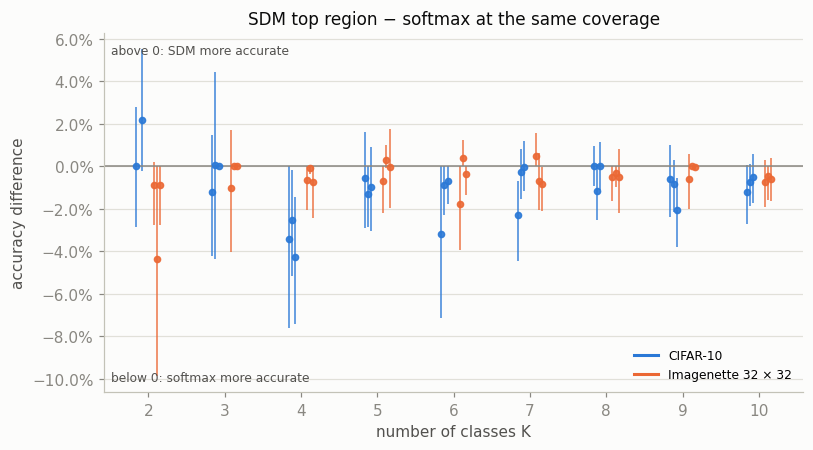

,SDM top α · CIFAR-10,SDM top α · Imagenette 32 × 32,coverage · CIFAR-10,coverage · Imagenette 32 × 32,SDM accuracy · CIFAR-10,SDM accuracy · Imagenette 32 × 32,softmax accuracy · CIFAR-10,softmax accuracy · Imagenette 32 × 32
k,,,,,,,,
2,0.80,0.78,19.4%,32.6%,97.8%,97.6%,96.7%,99.7%
3,0.92,0.93,17.9%,18.3%,98.1%,99.4%,98.4%,99.7%
4,0.92,0.95,27.7%,25.9%,95.3%,99.2%,98.7%,99.7%
5,0.95,0.95,28.0%,26.7%,98.1%,99.2%,99.0%,99.4%
6,0.95,0.95,22.1%,25.1%,98.0%,99.3%,99.6%,99.9%
7,0.95,0.95,25.1%,23.1%,98.2%,99.2%,99.1%,99.5%
8,0.95,0.95,26.9%,20.5%,98.4%,99.4%,98.8%,99.9%
9,0.93,0.95,28.2%,20.7%,97.7%,99.4%,98.8%,99.6%
10,0.90,0.90,28.6%,25.8%,97.8%,98.7%,98.6%,99.3%


In [9]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
has_region = runs["matched_accuracy_sdm_minus_softmax"].notna() if "matched_accuracy_sdm_minus_softmax" in runs else pd.Series(False, index=runs.index)
for (dataset, chain), group in runs[has_region].groupby(["dataset", "chain"]):
    x = group["k"] + offsets[dataset] + (chain - 1) * 0.04
    value = group["matched_accuracy_sdm_minus_softmax"]
    low = group["matched_accuracy_sdm_minus_softmax_interval"].map(lambda i: i[0])
    high = group["matched_accuracy_sdm_minus_softmax_interval"].map(lambda i: i[1])
    ax.errorbar(x, value, yerr=[value - low, high - value], fmt="o", markersize=4, color=COLORS[dataset],
                ecolor=COLORS[dataset], elinewidth=1, capsize=0, alpha=0.9)
ax.axhline(0, color=INK_MUTED, linewidth=1)
ax.text(0.01, 0.97, "above 0: SDM more accurate", transform=ax.transAxes, fontsize=8, color=INK_SECONDARY, va="top")
ax.text(0.01, 0.03, "below 0: softmax more accurate", transform=ax.transAxes, fontsize=8, color=INK_SECONDARY)
ax.set(title="SDM top region − softmax at the same coverage", ylabel="accuracy difference")
k_axis(ax)
percent(ax)
legend(ax, styles=(), loc="lower right")
plt.tight_layout()
plt.show()

table({"sdm_top_alpha": "SDM top α", "sdm_coverage_top": "coverage", "sdm_accuracy_top": "SDM accuracy",
       "matched_softmax_accuracy": "softmax accuracy"}, {"sdm_top_alpha": "{:.2f}"}) if has_region.any() else print("SDM formed no region in any run.")

## 8. Images from classes the model never saw

For K < 10, the validation images of the 10 − K classes not yet added are **out-of-distribution**: the model has to put them in one of its K classes, so every answer on them is wrong.

Left: the share of those images each rule answers anyway (lower is better): the softmax 95% threshold, and SDM at α ≥ 0.95. Right: how well each score separates in-set images (high) from excluded-class images (low), as an AUROC (0.5 = no separation, 1 = perfect).

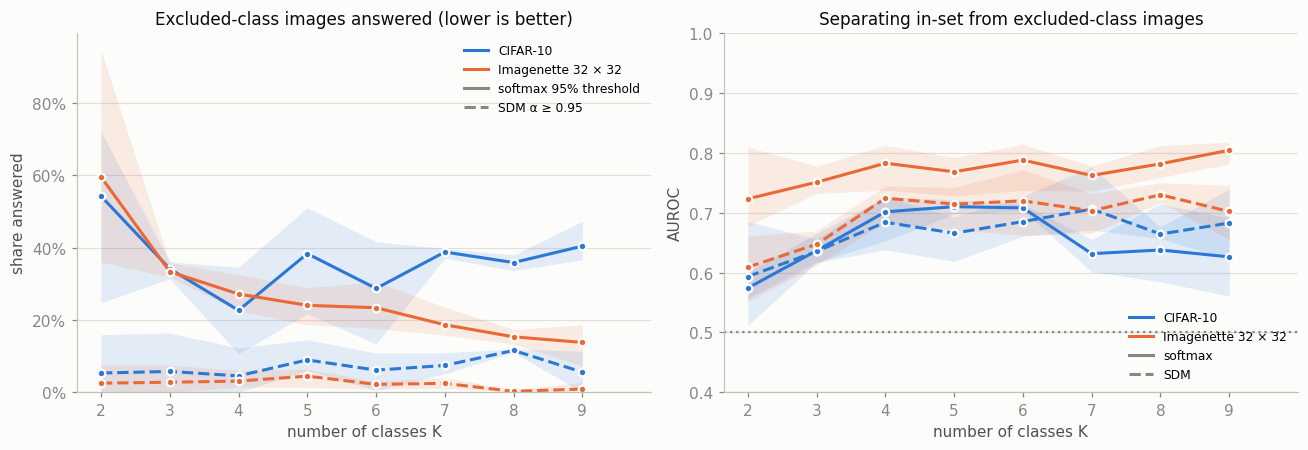

,softmax 95% answers · CIFAR-10,softmax 95% answers · Imagenette 32 × 32,SDM α≥0.95 answers · CIFAR-10,SDM α≥0.95 answers · Imagenette 32 × 32,SDM any-region answers · CIFAR-10,SDM any-region answers · Imagenette 32 × 32,SDM flags OOD · CIFAR-10,SDM flags OOD · Imagenette 32 × 32,softmax AUROC · CIFAR-10,softmax AUROC · Imagenette 32 × 32,SDM AUROC · CIFAR-10,SDM AUROC · Imagenette 32 × 32
k,,,,,,,,,,,,
2,54.3%,59.6%,5.3%,2.5%,33.8%,50.9%,27.2%,15.9%,0.574,0.723,0.593,0.609
3,34.2%,33.4%,5.7%,2.8%,30.3%,26.6%,16.8%,18.8%,0.637,0.751,0.635,0.647
4,22.7%,27.2%,4.5%,3.1%,28.7%,27.5%,13.6%,15.6%,0.701,0.783,0.684,0.724
5,38.4%,24.0%,8.9%,4.4%,31.2%,26.2%,11.7%,15.4%,0.710,0.768,0.666,0.714
6,28.7%,23.4%,6.1%,2.2%,30.8%,19.5%,13.0%,16.8%,0.708,0.788,0.685,0.720
7,38.8%,18.7%,7.4%,2.4%,24.4%,22.0%,12.7%,18.7%,0.632,0.762,0.706,0.703
8,35.9%,15.3%,11.6%,0.2%,31.0%,20.4%,14.2%,19.9%,0.638,0.782,0.664,0.730
9,40.4%,13.8%,5.6%,0.9%,28.0%,16.9%,15.1%,22.9%,0.626,0.804,0.683,0.702


In [10]:
ood = runs[runs["k"] < 10]
fig, (ax_answered, ax_auroc) = plt.subplots(1, 2, figsize=(12, 4.2))
for column, style in [("ood_softmax_answered_plain_95", "-"), ("ood_sdm_answered_095", "--")]:
    for dataset, group in ood.groupby(["dataset", "k"])[column].agg(["mean", "min", "max"]).reset_index().groupby("dataset"):
        ax_answered.plot(group["k"], group["mean"], color=COLORS[dataset], linestyle=style, marker="o", markersize=5, markeredgecolor=SURFACE, markeredgewidth=1.5)
        ax_answered.fill_between(group["k"], group["min"], group["max"], color=COLORS[dataset], alpha=0.12, linewidth=0)
for column, style in [("ood_softmax_auroc", "-"), ("ood_sdm_auroc", "--")]:
    for dataset, group in ood.groupby(["dataset", "k"])[column].agg(["mean", "min", "max"]).reset_index().groupby("dataset"):
        ax_auroc.plot(group["k"], group["mean"], color=COLORS[dataset], linestyle=style, marker="o", markersize=5, markeredgecolor=SURFACE, markeredgewidth=1.5)
        ax_auroc.fill_between(group["k"], group["min"], group["max"], color=COLORS[dataset], alpha=0.12, linewidth=0)
ax_answered.set(title="Excluded-class images answered (lower is better)", ylabel="share answered", ylim=(0, None))
percent(ax_answered)
ax_auroc.axhline(0.5, color=INK_MUTED, linestyle=":", linewidth=1.5)
ax_auroc.set(title="Separating in-set from excluded-class images", ylabel="AUROC", ylim=(0.4, 1.0))
for ax in (ax_answered, ax_auroc):
    k_axis(ax)
    ax.set_xticks(range(2, 10))
legend(ax_answered, styles=(("-", "softmax 95% threshold"), ("--", "SDM α ≥ 0.95")), loc="upper right")
legend(ax_auroc, loc="lower right")
plt.tight_layout()
plt.show()

runs_ood, runs = runs, ood  # table() summarizes `runs`; point it at the K < 10 runs for this table
ood_table = table({"ood_softmax_answered_plain_95": "softmax 95% answers", "ood_sdm_answered_095": "SDM α≥0.95 answers",
                   "ood_sdm_answered_any": "SDM any-region answers", "ood_sdm_flag_rate": "SDM flags OOD",
                   "ood_softmax_auroc": "softmax AUROC", "ood_sdm_auroc": "SDM AUROC"},
                  {"ood_softmax_auroc": "{:.3f}", "ood_sdm_auroc": "{:.3f}"})
runs = runs_ood
ood_table

## 9. What we learned

*(From our sweep: 2 datasets × 3 chains × K = 2…10 = 54 runs, each a freshly trained ResNet-18. Rerunning with other seeds will move individual numbers.)*

**1. With the same data and resolution, the two datasets end up equally hard.** At K = 10, validation accuracy is 77.1% on CIFAR-10 and 77.9% on Imagenette 32 × 32. Raw accuracy falls as classes are added (CIFAR-10 86% → 77%, Imagenette 93% → 78%), but chance-adjusted accuracy changes much less: it stays at 0.70–0.78 on CIFAR-10 and drifts from 0.85 to 0.75 on Imagenette. Between 2 and 10 classes, **each new class costs little**. The big drop from Imagenette to CIFAR-100 in notebook 10 needs many more classes, or more confusable ones.

**2. Calibration gets worse with more classes, and temperature scaling fixes it every time.** Raw ECE rises from about 5% at K = 2 to 11–13% from K = 4 on. After one fitted temperature, ECE is 2.4–4.1% at every K (CIFAR-10 at K = 2: 5.7%).

**3. The softmax 95% threshold answers more than half the images; the plain rule often lands just short.** Softmax answers 52–66% of CIFAR-10 and 58–79% of Imagenette validation images. Its accuracy reached 95% in 33 of 54 runs; on CIFAR-10 it averages 93.7–95.0%. That is the known optimism of the plain rule (notebook 04), and the conservative threshold is the safer choice.

**4. Whether SDM forms its strictest region does depend on the number of classes.** It formed an α = 0.95 region in 2/6 runs at K = 2, 4/6 at K = 3, 5–6/6 at K = 4–9, and **1/6 at K = 10**.
- The high end fits CIFAR-100, where SDM formed no region at all: the per-class rule has to hold for every class at once, and each extra class is another chance to fail.
- The low end is partly an artefact. With the epoch count fixed, the K = 2–3 models train on few images for few steps, and 5 of them stopped at 91–95% training accuracy.
- Where it forms, SDM's α ≥ 0.95 region answers 10–28% of images at 95–99.5% accuracy.

**5. At every K, softmax ranks right and wrong answers better than SDM.** Softmax AURC is lower than SDM's in all but a handful of runs, significantly so in 49 of 54 (paired bootstrap), and SDM is significantly better in none. SDM's excess AURC is about 1.5–1.7 times softmax's on both datasets.

**6. At the same coverage, SDM is never more accurate.** Comparing SDM's top region with a softmax threshold answering the same share of images, SDM was significantly more accurate in 0 of 53 runs and significantly less accurate in 6. On average it is 0.8 points less accurate.

**7. Unseen classes: SDM answers fewer of them, but only because it answers fewer images overall.**
- SDM at α ≥ 0.95 answers 4.6% of the excluded-class images, against 31.8% for the softmax 95% threshold.
- A softmax threshold set to SDM's coverage answers about as few: 9.9% against 9.2% on CIFAR-10, 2.3% against 3.7% on Imagenette.
- As a score for separating in-set from excluded-class images, softmax confidence is better in 37 of 48 runs. The exception is CIFAR-10 at K ≥ 7, where SDM is slightly better (AUROC 0.66–0.71 against 0.63–0.64).

**Bottom line:**
- From 2 to 10 classes, the number of classes moves accuracy and calibration modestly.
- It decides whether SDM can form its strictest region: most reliably at K = 4–9, rarely at K = 10, and not at all on CIFAR-100.
- It does not change the comparison. At every K, a temperature-scaled softmax threshold is as accurate as SDM at the same coverage, ranks answers better, and rejects as many unseen-class images.

**Limitations and next steps:**
- **Fixed epochs under-train the smallest tasks.** Repeat K = 2–4 with a fixed number of optimizer steps.
- **All models memorize their training images** (training accuracy about 99–100%). That blunts SDM's similarity signal; stronger augmentation or early stopping may change this.
- **These unseen classes are near out-of-distribution:** the same dataset, camera style and resolution. A far out-of-distribution test, such as SVHN digits shown to these models, is still missing.
- **One architecture.**
